# Protein MD exploration: coordinates vs. contact networks

This notebook follows the starter project:

1. Load ATLAS trajectories (CA atoms only).
2. Dimensionality reduction (DR) on the raw coordinates: PCA and t-SNE, coloured by time and RMSD.
3. Build a contact graph (contact map) for single frames.
4. Snapshots-to-Points: turn every frame's contact map into a vector and apply the same DR.
5. Compare the coordinate-based and network-based projections.

**Changes compared to the first version**
- Frames are sampled with a stride over the full 100 ns, instead of only the first 20 ns.
- RMSD formula fixed (it was too small by a factor of √3), and RMSD is now reported in Å.
- Contact threshold compared at 4.5, 6 and 8 Å. At 4.5 Å almost only chain neighbours are connected, so 8 Å is used for the network analysis.
- Contacts that never change are removed before DR (they carry no information and use a lot of memory).
- Network projections are drawn with lines between consecutive frames, as in the Snapshots-to-Points paper.
- Duplicate cells removed, plots combined into grids.

In [1]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

## Settings

All values you might want to change are here.

- `STRIDE`: keep every n-th frame. ATLAS has 10,001 frames over 100 ns (one per 10 ps), so `STRIDE = 5` gives about 2,000 frames that cover the whole simulation.
- `CONTACT_THRESHOLD`: distance (Å) below which two CA atoms count as "in contact".

In [2]:
proteins = ["16pk_A", "1a62_A", "1ab1_A"]

STRIDE = 5                      # every 5th frame -> ~2000 frames over the full 100 ns
CONTACT_THRESHOLD = 8.0         # Å, used for the network analysis
THRESHOLDS_TO_COMPARE = [4.5, 6.0, 8.0]   # Å, for the threshold comparison plots
RANDOM_STATE = 42               # makes t-SNE reproducible


def file_paths(protein):
    """Return the PDB (topology) and XTC (trajectory) paths for one ATLAS entry."""
    folder = f"{protein}_protein"
    pdb = f"{folder}/{protein}.pdb"
    # Note: the '_fit' trajectory is already aligned by ATLAS
    # (rotation and translation removed), so the RMSD below is effectively aligned RMSD.
    xtc = f"{folder}/{protein}_prod_R1_fit.xtc"
    return pdb, xtc

## 1. Load the trajectories

The PDB file tells MDTraj which atom is which (topology); the XTC file holds the coordinates of every frame.
We keep only the alpha carbons (CA): one atom per residue, so each frame becomes an N × 3 array.

MDTraj stores coordinates in **nanometres**. We convert to **ångströms** (× 10) right away, so every distance in this notebook is in Å.

In [3]:
data = {}

for protein in proteins:
    pdb, xtc = file_paths(protein)

    # stride=STRIDE loads only every STRIDE-th frame (faster and uses less memory)
    traj = md.load(xtc, top=pdb, stride=STRIDE)

    # Keep only the CA atoms
    ca = traj.topology.select("name CA")
    traj_ca = traj.atom_slice(ca)

    coords = traj_ca.xyz * 10          # (M, N, 3), converted from nm to Å
    time_ns = traj_ca.time / 1000      # MDTraj time is in ps

    data[protein] = {
        "traj": traj_ca,
        "coords": coords,
        "time_ns": time_ns,
        "X": coords.reshape(len(coords), -1),   # flattened: (M, 3N)
    }

    M, N, _ = coords.shape
    print(f"{protein}: {M} frames, {N} residues, "
          f"time {time_ns[0]:.0f}-{time_ns[-1]:.0f} ns, flattened shape {data[protein]['X'].shape}")

16pk_A: 2001 frames, 415 residues, time 0-100 ns, flattened shape (2001, 1245)
1a62_A: 2001 frames, 130 residues, time 0-100 ns, flattened shape (2001, 390)
1ab1_A: 2001 frames, 46 residues, time 0-100 ns, flattened shape (2001, 138)


## 2. RMSD to the first frame

RMSD (root mean square deviation) is the average distance between corresponding atoms of two structures:

$$\mathrm{RMSD} = \sqrt{\frac{1}{N}\sum_{i=1}^{N} \lVert x_i - x_i^{\mathrm{ref}} \rVert^2}$$

**Fix:** the first version averaged over atoms *and* the 3 coordinates, dividing by 3N instead of N,
which made all values √3 too small. Here we first sum over x, y, z (squared distance per atom), then average over atoms.

The plot of RMSD over time is a sanity check: compare it with the RMSD plot on the ATLAS page.

16pk_A: RMSD range 0.00-3.87 Å
1a62_A: RMSD range 0.00-3.55 Å
1ab1_A: RMSD range 0.00-1.83 Å


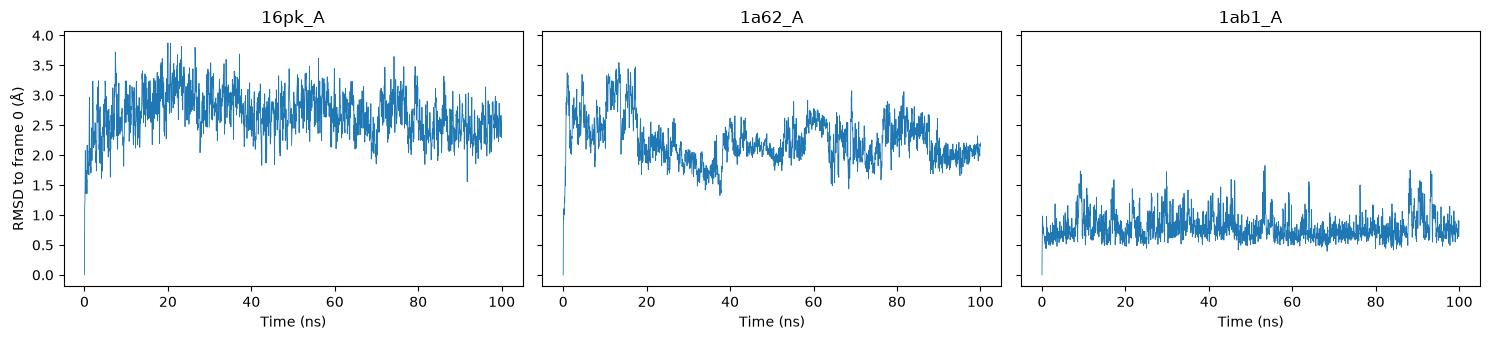

In [4]:
for protein in proteins:
    coords = data[protein]["coords"]
    reference = coords[0]

    # squared distance per atom (sum over x, y, z), mean over atoms, square root
    rmsd = np.sqrt(((coords - reference) ** 2).sum(axis=-1).mean(axis=-1))
    data[protein]["rmsd"] = rmsd

    print(f"{protein}: RMSD range {rmsd.min():.2f}-{rmsd.max():.2f} Å")

fig, axes = plt.subplots(1, len(proteins), figsize=(15, 3.5), sharey=True)
for ax, protein in zip(axes, proteins):
    ax.plot(data[protein]["time_ns"], data[protein]["rmsd"], lw=0.6)
    ax.set_title(protein)
    ax.set_xlabel("Time (ns)")
axes[0].set_ylabel("RMSD to frame 0 (Å)")
plt.tight_layout()
plt.show()

## 3. Dimensionality reduction on coordinates

Each frame is a point in 3N-dimensional space (all CA coordinates in one vector).
We project these points to 2D with:

- **PCA**: linear; finds the directions of largest variance. The explained variance ratio tells how much of the total movement the 2D plot captures.
- **t-SNE**: non-linear; tries to keep similar frames close together. Good at showing clusters, but distances between clusters and cluster sizes are not meaningful.

Each projection is coloured twice: by simulation time and by RMSD to the first frame.

In [5]:
for protein in proteins:
    X = data[protein]["X"]

    pca = PCA(n_components=2)
    data[protein]["coord_pca"] = pca.fit_transform(X)
    data[protein]["coord_pca_var"] = pca.explained_variance_ratio_

    # init="pca" gives t-SNE a more stable starting layout than random initialisation
    data[protein]["coord_tsne"] = TSNE(
        n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE
    ).fit_transform(X)

    v = data[protein]["coord_pca_var"]
    print(f"{protein}: coordinate PCA explained variance PC1 {v[0]:.1%}, PC2 {v[1]:.1%}, total {v.sum():.1%}")

16pk_A: coordinate PCA explained variance PC1 32.8%, PC2 16.0%, total 48.9%
1a62_A: coordinate PCA explained variance PC1 37.6%, PC2 22.5%, total 60.1%
1ab1_A: coordinate PCA explained variance PC1 31.7%, PC2 11.9%, total 43.6%


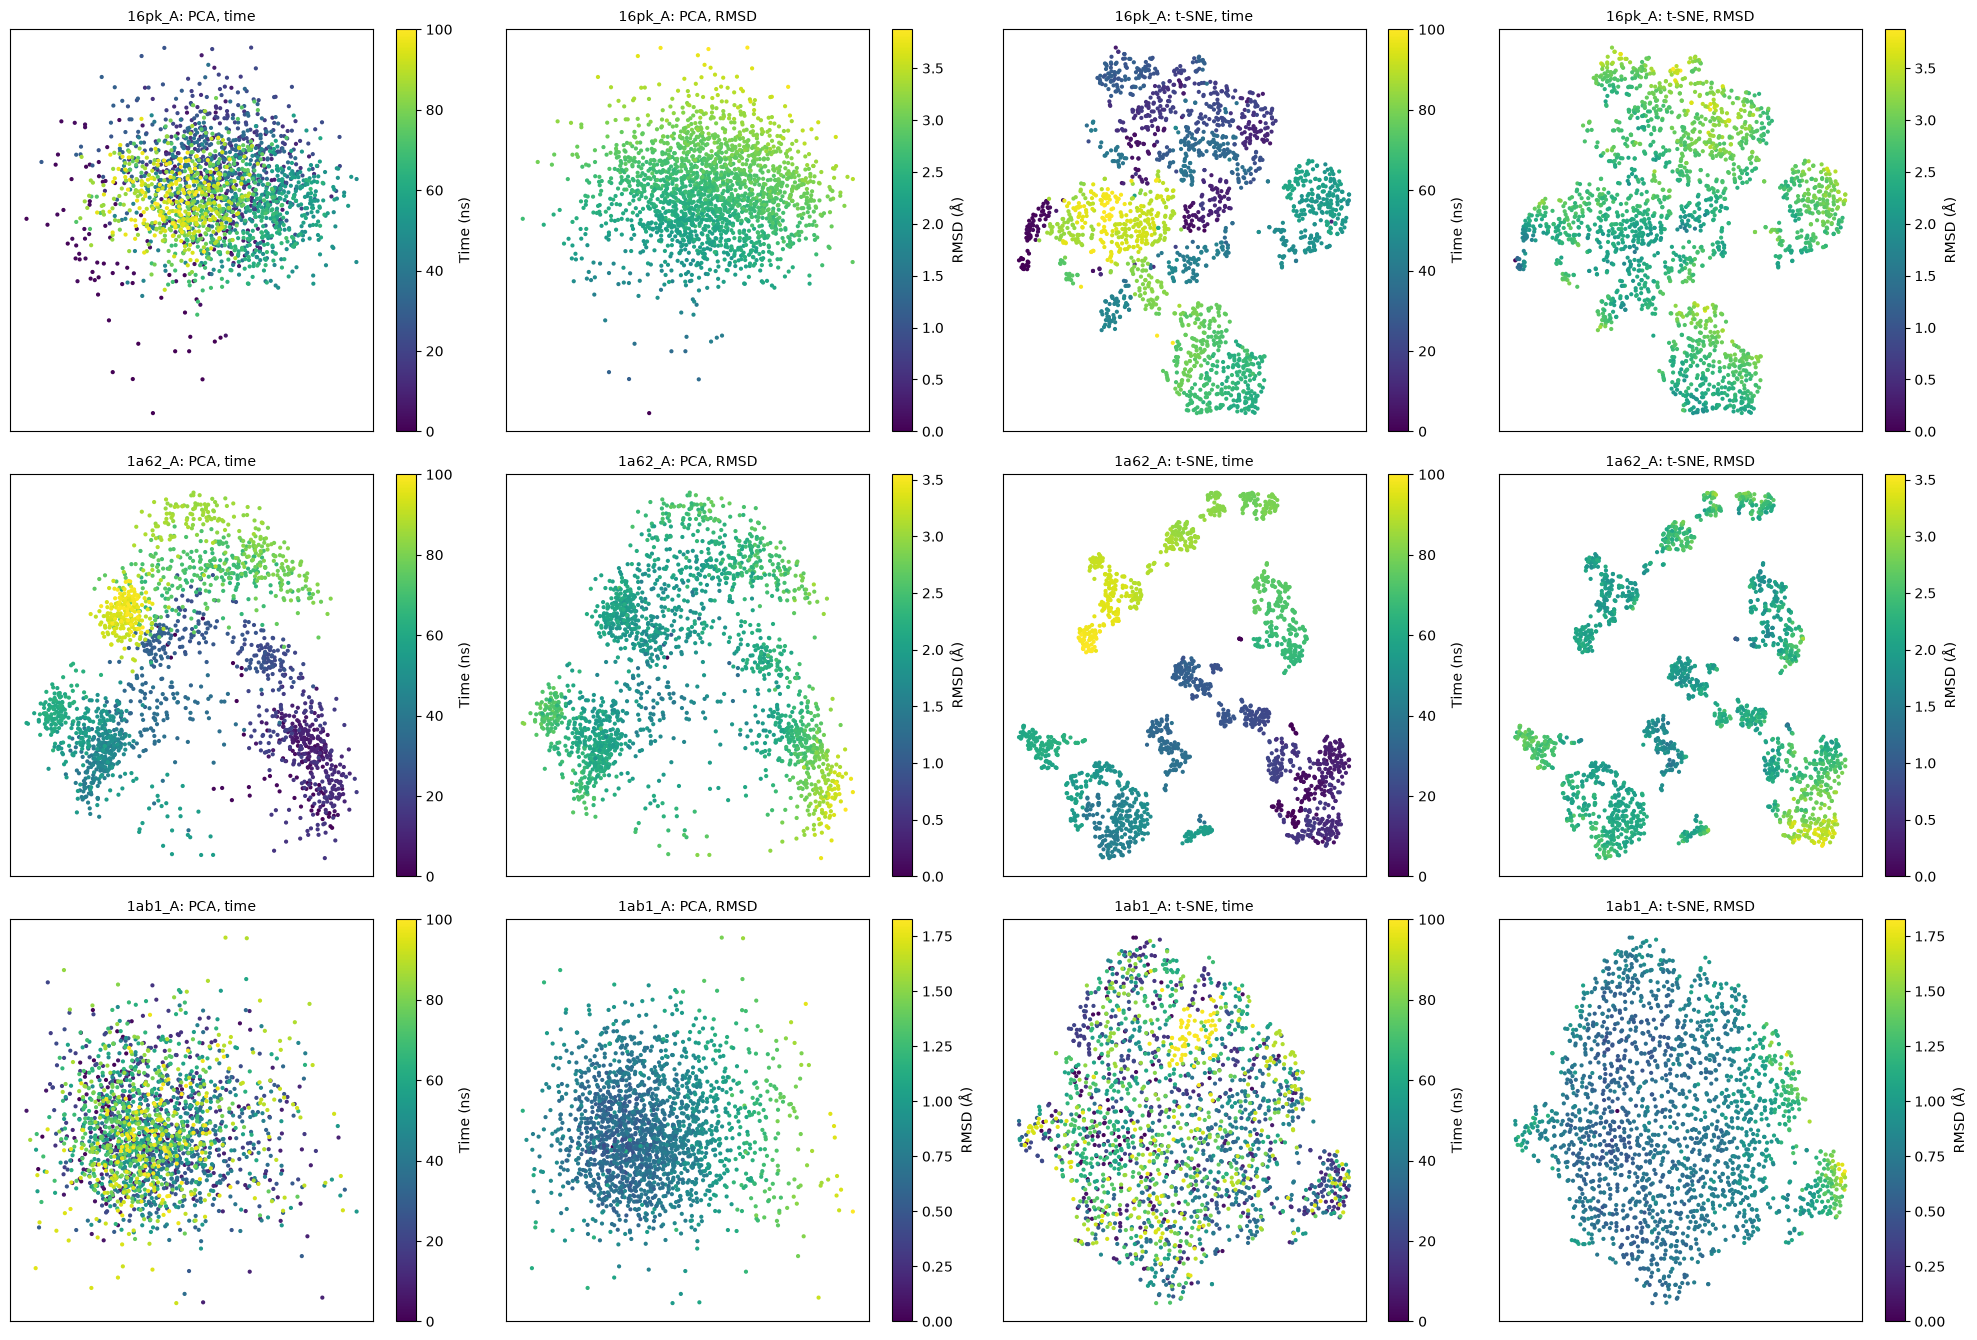

In [6]:
def plot_projection(ax, Y, colour, title, colour_label, connect=False):
    """Scatter a 2D projection. With connect=True, consecutive frames are joined by a thin line."""
    if connect:
        ax.plot(Y[:, 0], Y[:, 1], lw=0.3, c="gray", alpha=0.6, zorder=1)
    sc = ax.scatter(Y[:, 0], Y[:, 1], c=colour, s=4, zorder=2)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(sc, ax=ax, label=colour_label)


# Rows: proteins. Columns: PCA/t-SNE, coloured by time/RMSD.
fig, axes = plt.subplots(len(proteins), 4, figsize=(20, 4.5 * len(proteins)))
for row, protein in zip(axes, proteins):
    d = data[protein]
    plot_projection(row[0], d["coord_pca"],  d["time_ns"], f"{protein}: PCA, time",   "Time (ns)")
    plot_projection(row[1], d["coord_pca"],  d["rmsd"],    f"{protein}: PCA, RMSD",   "RMSD (Å)")
    plot_projection(row[2], d["coord_tsne"], d["time_ns"], f"{protein}: t-SNE, time", "Time (ns)")
    plot_projection(row[3], d["coord_tsne"], d["rmsd"],    f"{protein}: t-SNE, RMSD", "RMSD (Å)")
plt.tight_layout()
plt.show()

**What to look for**
- Separate groups of points can mean distinct states. Check whether they also differ in RMSD.
- A smooth colour gradient along an axis usually means the projection mainly shows the protein slowly drifting away from its starting structure.
- Early and late frames in the same region means the protein revisits states.
- **Caution with t-SNE:** consecutive frames are always very similar, so t-SNE tends to form clusters of consecutive frames even without real distinct states. A cluster of a single colour (one time period) is not necessarily a separate conformation.

## 4. Contact maps (graph of a single frame)

Every CA atom is a node; two nodes are connected if their distance is below a threshold.
The adjacency matrix of this graph is the **contact map**.

`pdist` computes all pairwise distances at once. It returns only the upper triangle (each pair once),
and `squareform` turns that into the full N × N matrix.

**Threshold:** consecutive CA atoms along the chain are always about 3.8 Å apart. With a 4.5 Å threshold,
almost only these chain neighbours are connected (the diagonal), and real contacts between different parts of the protein are missed.
Below we compare three thresholds; compare them with the contact map on the ATLAS website.

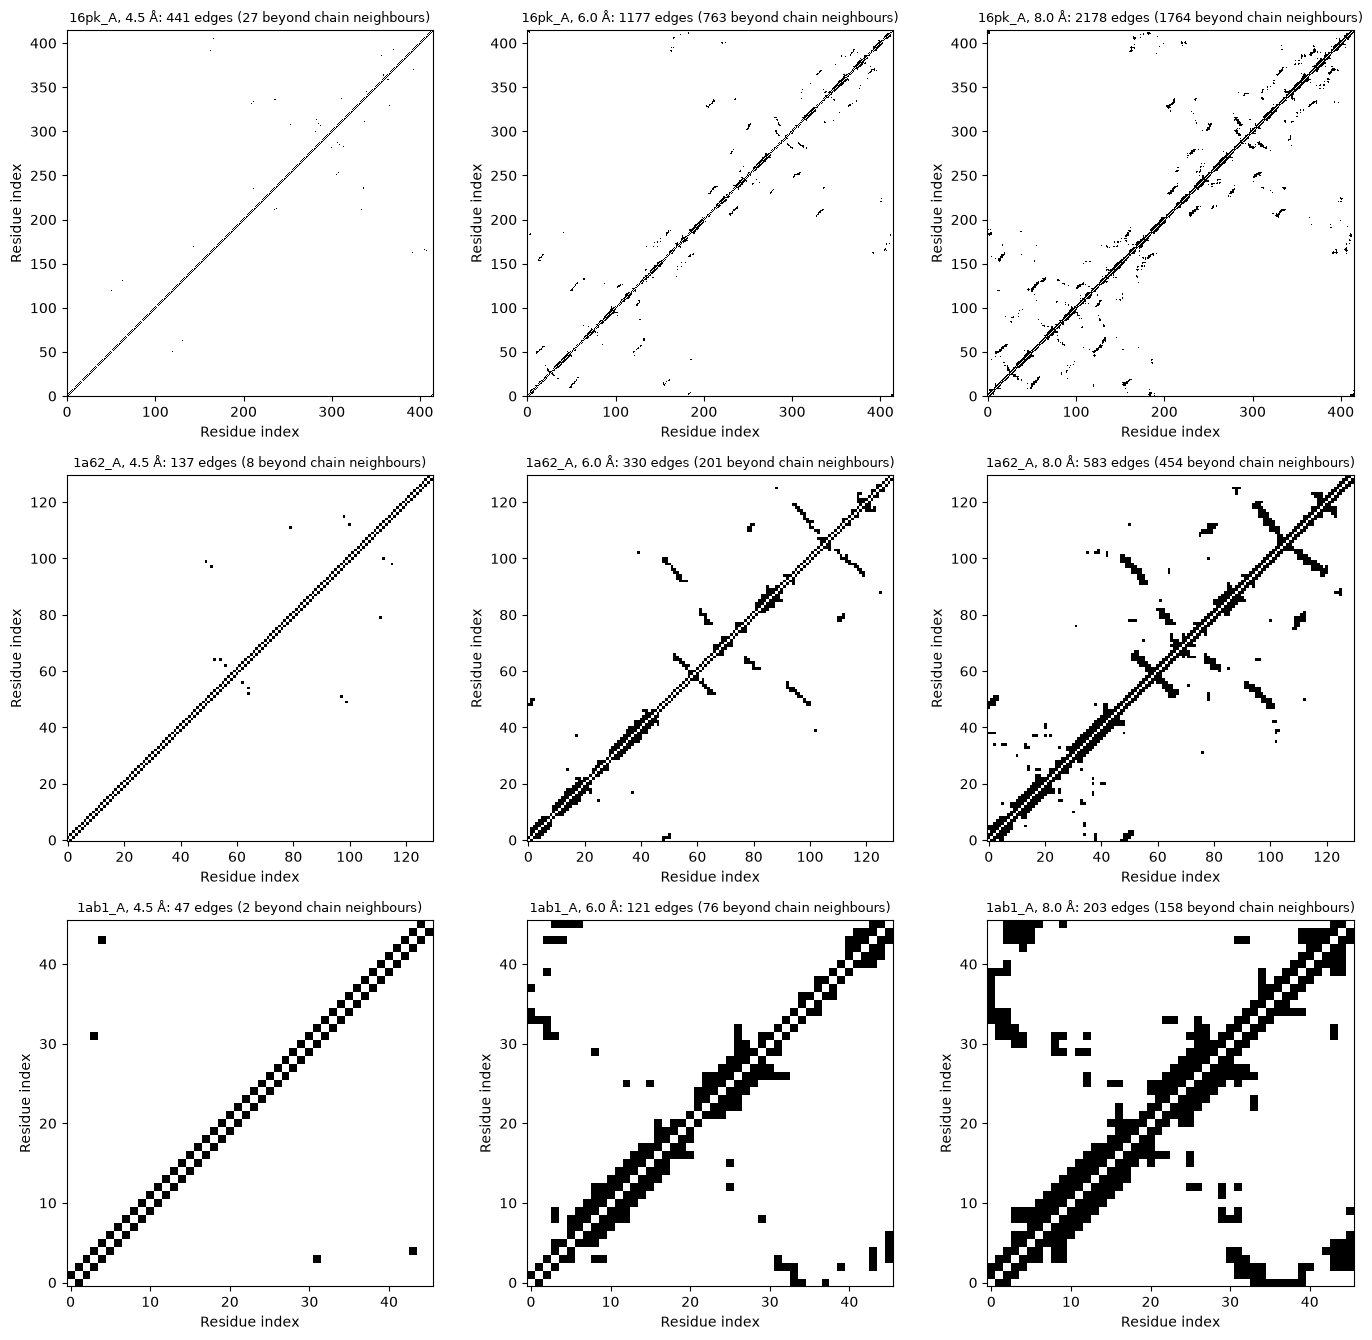

In [7]:
def contact_map(frame_coords, threshold):
    """Binary N x N contact map for one frame (coordinates in Å)."""
    distances = squareform(pdist(frame_coords))      # N x N distance matrix in Å
    adjacency = (distances < threshold).astype(int)
    np.fill_diagonal(adjacency, 0)                   # no self-loops
    return adjacency


fig, axes = plt.subplots(len(proteins), len(THRESHOLDS_TO_COMPARE), figsize=(14, 4.5 * len(proteins)))
for row, protein in zip(axes, proteins):
    N = data[protein]["coords"].shape[1]
    for ax, thr in zip(row, THRESHOLDS_TO_COMPARE):
        A = contact_map(data[protein]["coords"][0], thr)
        n_edges = A.sum() // 2
        n_chain = N - 1                               # edges between consecutive residues
        ax.imshow(A, origin="lower", cmap="Greys", interpolation="nearest")
        ax.set_title(f"{protein}, {thr} Å: {n_edges} edges ({n_edges - n_chain} beyond chain neighbours)", fontsize=9)
        ax.set_xlabel("Residue index"); ax.set_ylabel("Residue index")
plt.tight_layout()
plt.show()

### Contact map over time

The same protein at five moments in the simulation, using the chosen threshold.
Changes between these maps are what the network analysis below picks up.

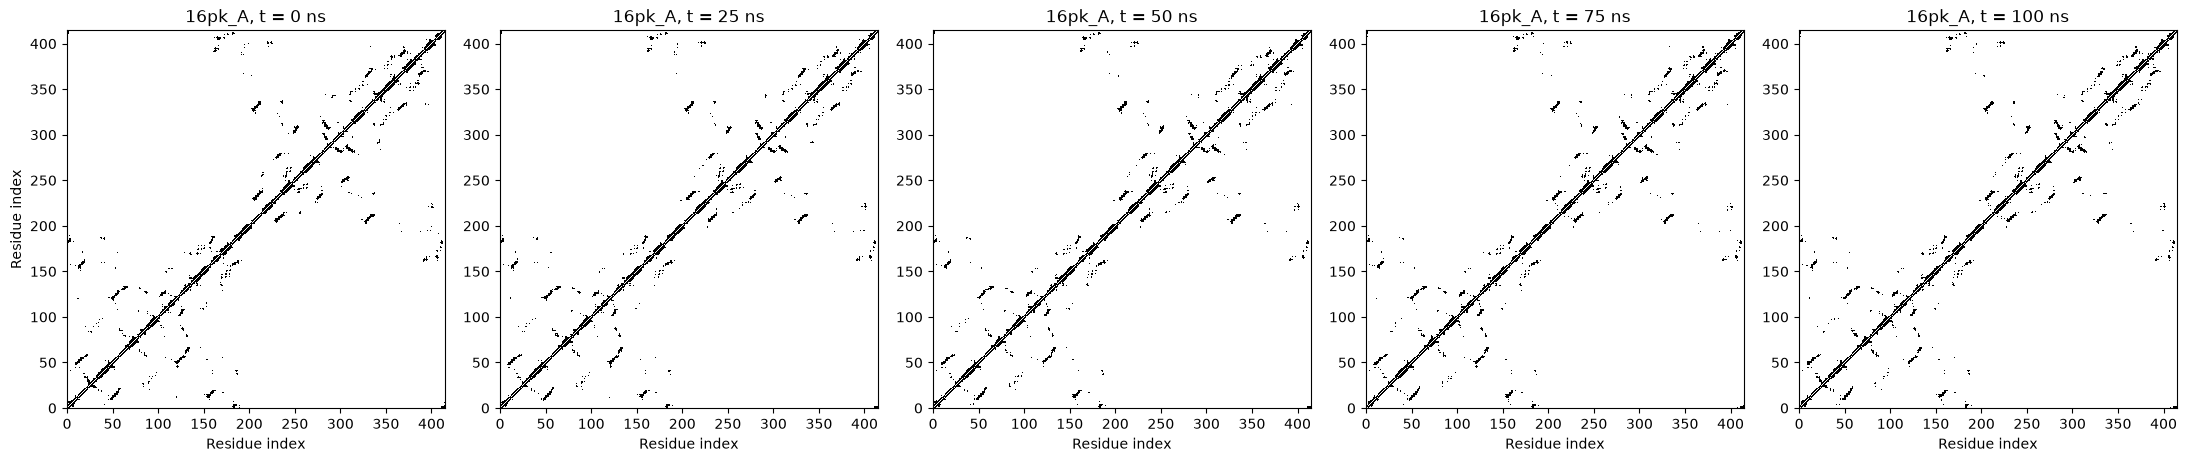

In [8]:
protein = "16pk_A"
coords = data[protein]["coords"]
time_ns = data[protein]["time_ns"]
frame_indices = np.linspace(0, len(coords) - 1, 5).astype(int)   # 5 evenly spaced frames

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, f in zip(axes, frame_indices):
    ax.imshow(contact_map(coords[f], CONTACT_THRESHOLD), origin="lower", cmap="Greys", interpolation="nearest")
    ax.set_title(f"{protein}, t = {time_ns[f]:.0f} ns")
    ax.set_xlabel("Residue index")
axes[0].set_ylabel("Residue index")
plt.tight_layout()
plt.show()

## 5. Dynamic network: Snapshots-to-Points

Following the Snapshots-to-Points idea, each frame's contact map becomes one feature vector:
the upper triangle of the adjacency matrix (N(N-1)/2 binary values, one per residue pair).
Then the same DR methods are applied as for the coordinates.

**Removing constant contacts:** most pairs are either always in contact (e.g. chain neighbours) or never
(residues on opposite sides of the protein). These columns are identical in every frame, so they carry no information
for DR. Dropping them makes the computation much lighter (16pk_A has 85,905 pairs).
The number of remaining *varying* contacts is printed; if it is very small, the projection will collapse onto a few points.

In [9]:
def contact_features(coords, threshold):
    """One row per frame: the upper triangle of the contact map as booleans."""
    # pdist returns exactly the upper triangle (each residue pair once), in a fixed order
    return np.array([pdist(frame) < threshold for frame in coords])


network = {}

for protein in proteins:
    F = contact_features(data[protein]["coords"], CONTACT_THRESHOLD)   # (M, N(N-1)/2), bool

    # Keep only contacts that change at least once during the simulation
    varying = F.any(axis=0) & ~F.all(axis=0)
    F_var = F[:, varying].astype(np.float32)

    network[protein] = {"features": F_var, "varying_mask": varying}
    print(f"{protein}: {F.shape[1]} residue pairs, {varying.sum()} contacts change over time")

16pk_A: 85905 residue pairs, 1331 contacts change over time
1a62_A: 8385 residue pairs, 439 contacts change over time
1ab1_A: 1035 residue pairs, 102 contacts change over time


In [10]:
import pandas as pd

p = "1a62_A"
coords = data[p]["coords"]
N = coords.shape[1]

F_all = contact_features(coords, CONTACT_THRESHOLD)    # (frames, pairs), True = contact
I, J = np.triu_indices(N, k=1)                         # residue pair of each column (same order as pdist)
pair_names = [f"{i}-{j}" for i, j in zip(I, J)]

table = pd.DataFrame(F_all.astype(int), columns=pair_names)
table.index = np.round(data[p]["time_ns"], 2)
table.index.name = "time (ns)"
print(table.shape)          # (frames, residue pairs)
table.iloc[:5, :8]          # first 5 frames, first 8 pairs

(2001, 8385)


,0-1,0-2,0-3,0-4,0-5,0-6,0-7,0-8
time (ns),,,,,,,,
0.00,1,1,0,1,1,0,0,0
0.05,1,1,0,1,1,0,0,0
0.10,1,1,0,1,0,0,0,0
0.15,1,1,0,1,0,0,0,0
0.20,1,1,0,1,1,0,0,0


In [11]:
always_on  = F_all.all(axis=0)          # contact in every frame
always_off = ~F_all.any(axis=0)         # contact in no frame
varying    = ~always_on & ~always_off   # contact in some frames but not others

print(f"{p}: {len(pair_names)} residue pairs")
print(f"  always in contact (constant 1): {always_on.sum()}")
print(f"  never in contact  (constant 0): {always_off.sum()}")
print(f"  changing over time (kept):      {varying.sum()}")

# One example of each kind, plus the two contacts from the distance plot
examples = [pair_names[np.flatnonzero(always_on)[0]],
            pair_names[np.flatnonzero(always_off)[-1]],
            "103-106", "38-103"]
print("\nFraction of frames with contact:")
print(table[examples].mean().round(2))
table[examples].iloc[::200]             # every 200th frame (every 10 ns)

1a62_A: 8385 residue pairs
  always in contact (constant 1): 425
  never in contact  (constant 0): 7521
  changing over time (kept):      439

Fraction of frames with contact:
0-1        1.00
123-128    0.00
103-106    0.60
38-103     0.22
dtype: float64


,0-1,123-128,103-106,38-103
time (ns),,,,
0.0,1,0,1,0
10.0,1,0,1,0
20.0,1,0,1,0
30.0,1,0,1,0
40.0,1,0,1,0
50.0,1,0,1,0
60.0,1,0,1,0
70.0,1,0,0,0
80.0,1,0,0,1


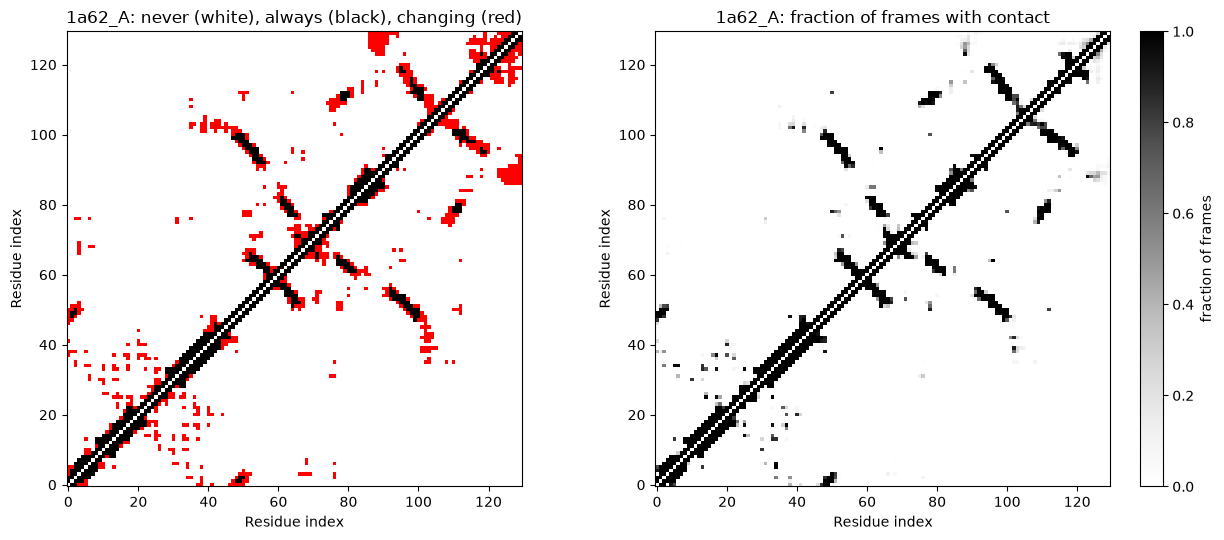

In [12]:
from matplotlib.colors import ListedColormap

kind = np.zeros(len(pair_names))
kind[always_on] = 1
kind[varying] = 2

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].imshow(squareform(kind), origin="lower", interpolation="nearest",
               cmap=ListedColormap(["white", "black", "red"]), vmin=0, vmax=2)
axes[0].set_title(f"{p}: never (white), always (black), changing (red)")

im2 = axes[1].imshow(squareform(F_all.mean(axis=0)), origin="lower", interpolation="nearest",
                     cmap="Greys", vmin=0, vmax=1)
axes[1].set_title(f"{p}: fraction of frames with contact")
plt.colorbar(im2, ax=axes[1], label="fraction of frames")

for ax in axes:
    ax.set_xlabel("Residue index"); ax.set_ylabel("Residue index")
plt.tight_layout()
plt.show()

Why it doesn’t change the result

Dimensionality reduction only cares about how frames differ from each other. A constant column has the same value in every frame, so it never contributes a difference.

Distances (t-SNE): the distance between two frames counts how many contacts differ. For pair 0–1, both frames have a 1, so the difference is 0. For pair 123–128, both have a 0, so again 0. Constant columns add nothing to any distance.
PCA: PCA first subtracts each column’s average, which turns a constant column into all zeros. It has zero variance, so PCA can’t use it for any axis.

So with or without the 7,946 constant columns, you’d get the same projections.

Why we remove them anyway

1. Memory and speed. This matters most for the large protein. For 16pk_A, the full table is 2,001 frames × 85,905 pairs, about 690 MB in memory. With only the 1,331 varying pairs, it’s about 11 MB, roughly 65 times smaller. PCA, t-SNE and the windowing in section 7 all run much faster.

2. Some normalizations break on them. Min-max and z-score divide by a column’s range or standard deviation, which is 0 for a constant column, so you’d divide by zero. scikit-learn quietly handles this, but other tools may return errors or NaN values.

3. Clarity. The kept columns are exactly the contacts that can tell frames apart. That makes later steps easier to interpret: the 439 contacts for 1a62_A are the only candidates that can explain any pattern in the projection.

The “no effect” argument holds for the Euclidean distance the notebook uses. It doesn’t hold for every distance. Jaccard distance, which I mentioned as an alternative, divides the number of differing contacts by the total number of contacts present in either frame. The 425 always-present contacts increase that total, so they make every difference look relatively smaller. If you ever switch to Jaccard, you’d need to decide whether to include them. Including them arguably makes more sense there, since a change of 10 contacts means more in a small network than in a large one.

For 1a62_A, PCA receives a table of 2,001 rows × 439 columns:

each row is one frame (a point to be placed on the map),
each column is one changing contact, such as 103–106 or 38–103,
each value is 1 (in contact) or 0 (not).

In the notebook, that’s network["1a62_A"]["features"]:

python
PCA(n_components=2).fit_transform(network[p]["features"])   # input: (2001, 439) -> output: (2001, 2)

The output is a table of 2,001 rows × 2 columns: an x and a y position for each frame. Those are the dots you plot.

In [ ]:
for protein in proteins:
    F = network[protein]["features"]

    pca = PCA(n_components=2)
    network[protein]["pca"] = pca.fit_transform(F)
    network[protein]["pca_var"] = pca.explained_variance_ratio_

    # Euclidean distance on binary vectors = sqrt(number of contacts that differ).
    network[protein]["tsne"] = TSNE(
        n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE
    ).fit_transform(F)

    v = network[protein]["pca_var"]
    print(f"{protein}: network PCA explained variance PC1 {v[0]:.1%}, PC2 {v[1]:.1%}, total {v.sum():.1%}")

16pk_A: network PCA explained variance PC1 3.6%, PC2 3.1%, total 6.7%
1a62_A: network PCA explained variance PC1 10.9%, PC2 5.4%, total 16.3%
1ab1_A: network PCA explained variance PC1 8.2%, PC2 7.6%, total 15.8%


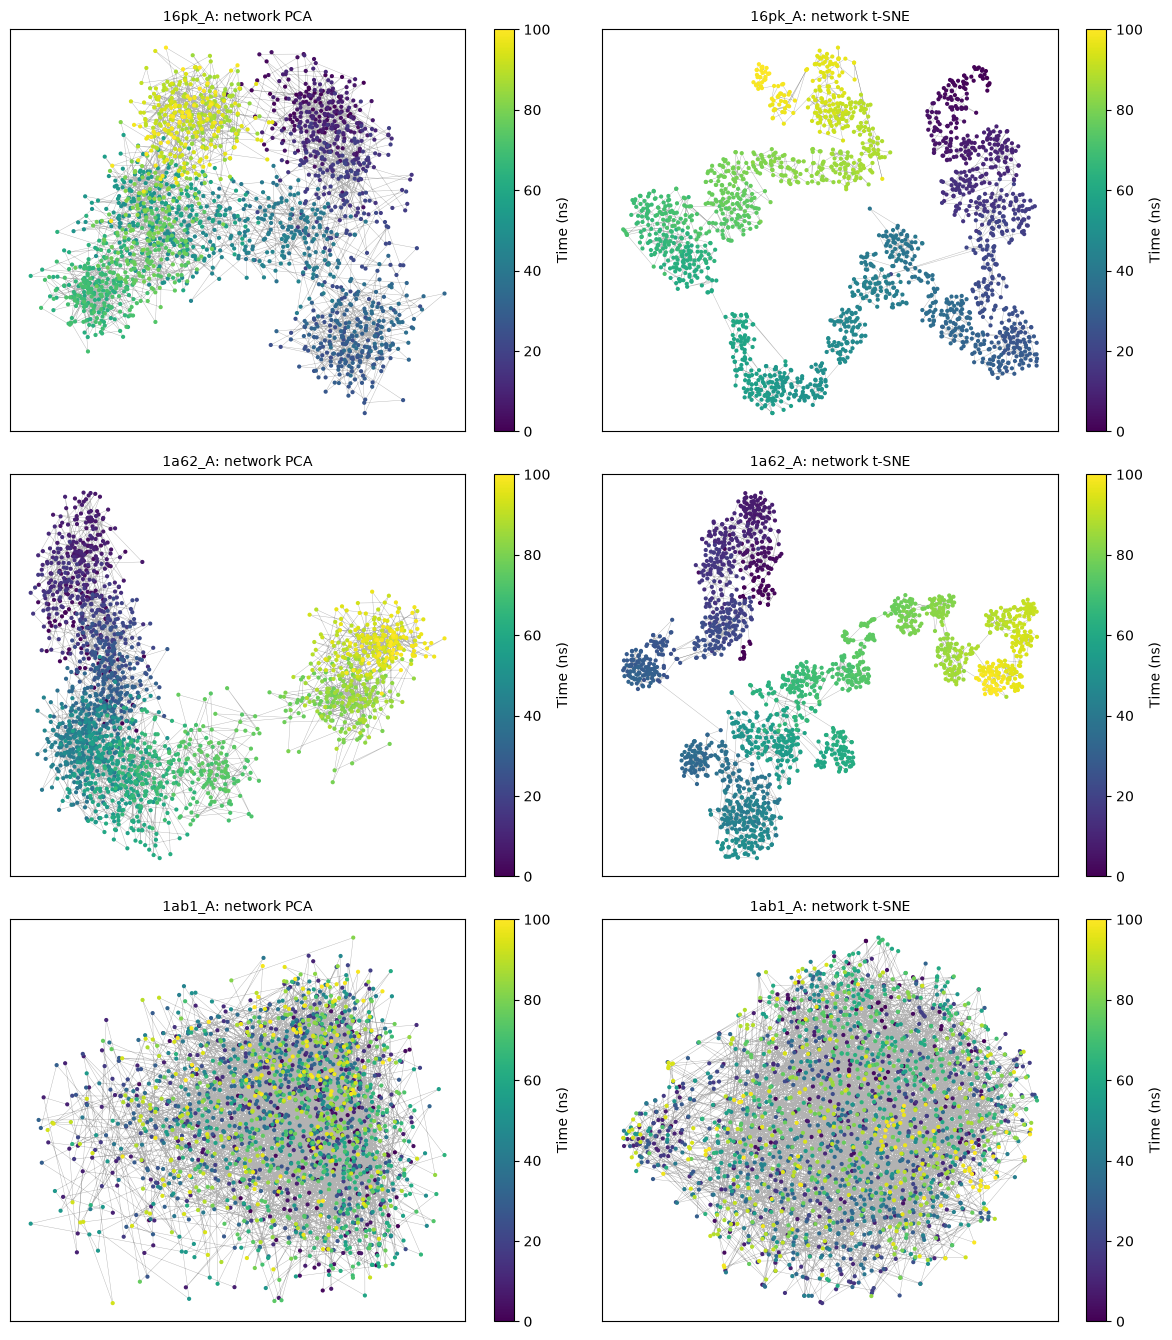

In [14]:
# Network projections, with consecutive frames connected (the trajectory through network space)
fig, axes = plt.subplots(len(proteins), 2, figsize=(12, 4.5 * len(proteins)))
for row, protein in zip(axes, proteins):
    t = data[protein]["time_ns"]
    plot_projection(row[0], network[protein]["pca"],  t, f"{protein}: network PCA",   "Time (ns)", connect=True)
    plot_projection(row[1], network[protein]["tsne"], t, f"{protein}: network t-SNE", "Time (ns)", connect=True)
plt.tight_layout()
plt.show()

## 6. Coordinates vs. network

Side by side for each protein: the coordinate-based projection (step 3) and the network-based projection (step 5), both coloured by time.

Contact maps only depend on distances *within* the protein, so they ignore rotation and translation of the whole molecule.
Differences between the two columns therefore show what changes in the protein's *internal* structure,
as opposed to its overall position and shape in space.

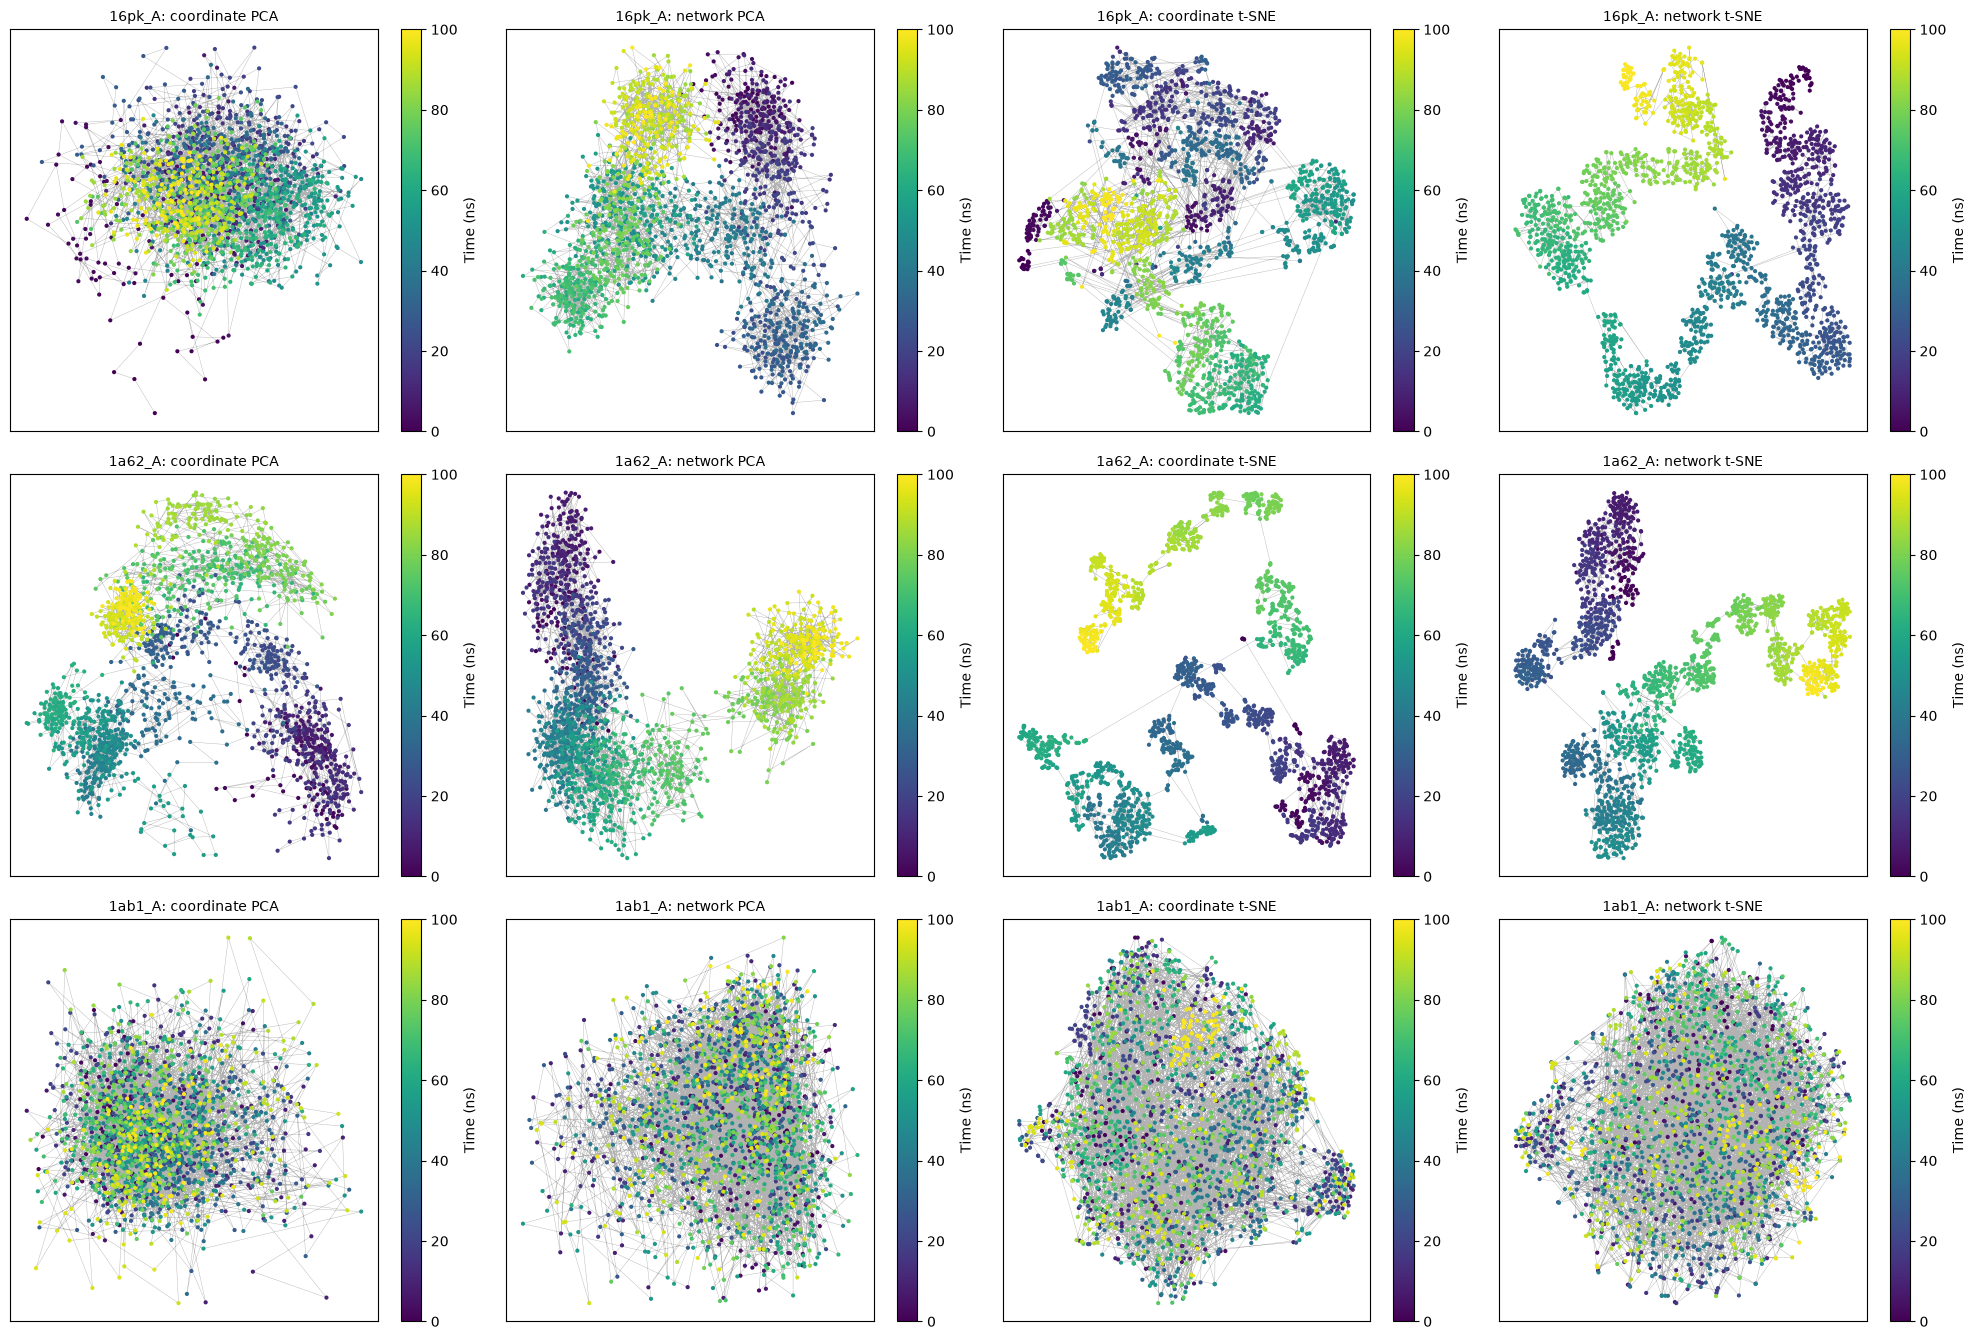

protein  residues  max RMSD (Å)  coord PCA 2D  varying contacts  network PCA 2D
16pk_A        415          3.87         48.9%              1331            6.7%
1a62_A        130          3.55         60.1%               439           16.3%
1ab1_A         46          1.83         43.6%               102           15.8%


In [15]:
fig, axes = plt.subplots(len(proteins), 4, figsize=(20, 4.5 * len(proteins)))
for row, protein in zip(axes, proteins):
    t = data[protein]["time_ns"]
    plot_projection(row[0], data[protein]["coord_pca"],  t, f"{protein}: coordinate PCA",  "Time (ns)", connect=True)
    plot_projection(row[1], network[protein]["pca"],     t, f"{protein}: network PCA",     "Time (ns)", connect=True)
    plot_projection(row[2], data[protein]["coord_tsne"], t, f"{protein}: coordinate t-SNE", "Time (ns)", connect=True)
    plot_projection(row[3], network[protein]["tsne"],    t, f"{protein}: network t-SNE",   "Time (ns)", connect=True)
plt.tight_layout()
plt.show()

# Summary table
print(f"{'protein':<8} {'residues':>8} {'max RMSD (Å)':>13} {'coord PCA 2D':>13} {'varying contacts':>17} {'network PCA 2D':>15}")
for protein in proteins:
    print(f"{protein:<8} {data[protein]['coords'].shape[1]:>8} {data[protein]['rmsd'].max():>13.2f} "
          f"{data[protein]['coord_pca_var'].sum():>13.1%} {network[protein]['varying_mask'].sum():>17} "
          f"{network[protein]['pca_var'].sum():>15.1%}")

**How to read the explained variance comparison**

Explained variance only says how much of the variation fits in two dimensions; it does not say which representation is "better".
It also depends strongly on the number of varying features: with only a few varying contacts, PCA can explain a large share
of the variance even though the plot shows very little (points collapse onto a few positions).
Always look at the plots together with the number of varying contacts.

In [16]:
# Save results so the slow steps (t-SNE, contact features) don't need to be rerun
for protein in proteins:
    np.savez(
        f"{protein}_analysis.npz",
        time_ns=data[protein]["time_ns"],
        rmsd=data[protein]["rmsd"],
        coord_pca=data[protein]["coord_pca"],
        coord_tsne=data[protein]["coord_tsne"],
        network_pca=network[protein]["pca"],
        network_tsne=network[protein]["tsne"],
        contact_threshold=CONTACT_THRESHOLD,
    )

## 7. Reducing Snapshots to Points: trying the paper's options

Van den Elzen et al. (2016) turn every snapshot of a dynamic network into one vector, project all vectors to 2D, and connect consecutive points with a line.
Step 5 above already does the basic version. This section adds the paper's extra ideas:

- **A. Sliding windows with overlap** (paper Section 3.3, Fig. 3): average contact maps over several frames, so each contact becomes a frequency between 0 and 1 instead of flickering between 0 and 1.
- **B. Normalization** (Section 3.4, Fig. 4): none, binarization, min-max, z-score.
- **C. Time vs. PC1** (Figs. 9a, 11a): shows *when* states and transitions happen.
- **D. Colouring by derived attributes** (Section 3.6): number of contacts, RMSD.
- **E. Representative states** (Figs. 1, 8): group the snapshots into states and show the average contact map of each.

**How to read the projections (paper Section 3.6)**
- Cluster with **one colour** (one time period) → **stable state**.
- Cluster with **many colours** → **recurring state** (the network returns to it at different times).
- **Lines between clusters** → **transitions**.
- **Isolated points** → **outliers**.

In [17]:
PROTEIN = "1a62_A"     # protein to study in A, B, D and E (C shows all proteins)


def window_starts(n_frames, width, step):
    """Start index of every window. Overlap between windows = (width - step) / width."""
    return np.arange(0, n_frames - width + 1, step)


def window_mean(values, width, step):
    """Average any per-frame array (features, RMSD, time) over sliding windows."""
    starts = window_starts(len(values), width, step)
    return np.array([values[s:s + width].mean(axis=0) for s in starts])


def step_for(width, overlap):
    """Step size that gives the requested overlap for a given window width."""
    return max(1, int(round(width * (1 - overlap))))

### A. Window width and overlap

Each frame is 50 ps apart (with `STRIDE = 5`). A window of 20 frames therefore covers 1 ns.
Within a window, each contact gets its **frequency**: the fraction of frames in which it was present.

The grid below varies the window width (rows) and the overlap between consecutive windows (columns), as in Fig. 3 of the paper.
A window width of 1 is the original, unwindowed version from step 5.

**What to look for:** more overlap and wider windows smooth the trajectory. The paper reports that more overlap reveals more structure.
Too wide windows blur short events, so look for the setting where clusters and transitions are clearest.

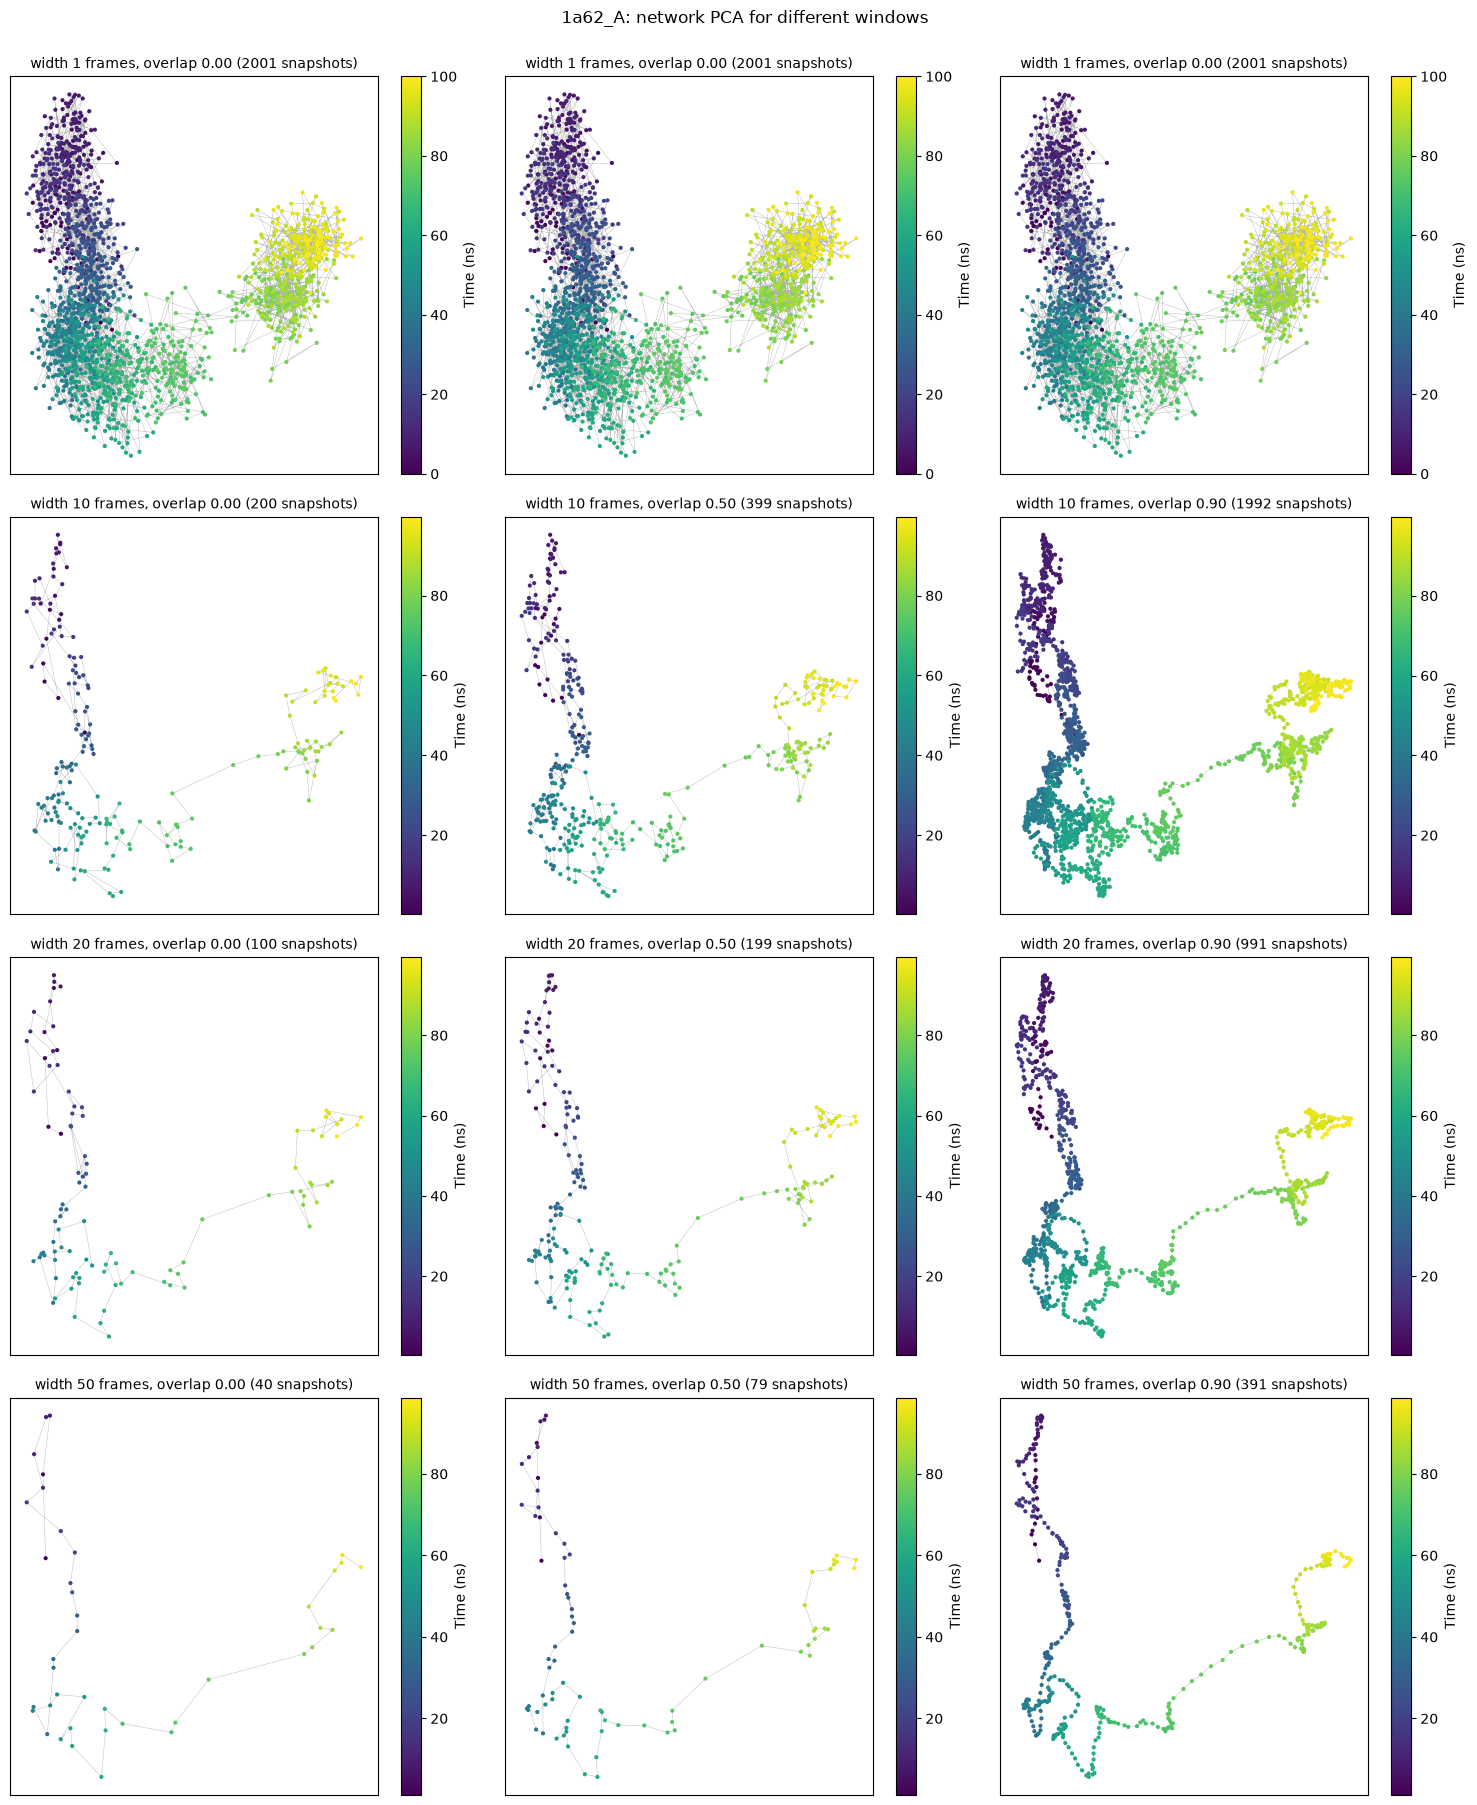

In [18]:
widths = [1, 10, 20, 50]          # frames per window
overlaps = [0.0, 0.5, 0.9]

F = network[PROTEIN]["features"]
t = data[PROTEIN]["time_ns"]

fig, axes = plt.subplots(len(widths), len(overlaps), figsize=(15, 4.5 * len(widths)))
for row, width in zip(axes, widths):
    for ax, overlap in zip(row, overlaps):
        step = step_for(width, overlap)
        W = window_mean(F, width, step)
        tW = window_mean(t, width, step)
        Y = PCA(n_components=2).fit_transform(W)
        real_overlap = (width - step) / width
        plot_projection(ax, Y, tW, f"width {width} frames, overlap {real_overlap:.2f} ({len(W)} snapshots)",
                        "Time (ns)", connect=True)
fig.suptitle(f"{PROTEIN}: network PCA for different windows", y=1.0)
plt.tight_layout()
plt.show()

### B. Normalization

Choose one window setting from A (`WIDTH`, `OVERLAP`) and compare the four normalizations from the paper:

- **none**: contact frequencies as they are.
- **binarized**: 1 if the contact appeared at all in the window, else 0 (the paper's definition).
- **min-max**: every contact rescaled to the range 0–1.
- **z-score**: every contact rescaled to mean 0 and standard deviation 1. Rare contacts get as much weight as common ones.

The paper prefers z-score for PCA, but notes that no normalization already shows much of the structure, and that the best choice depends on the data.

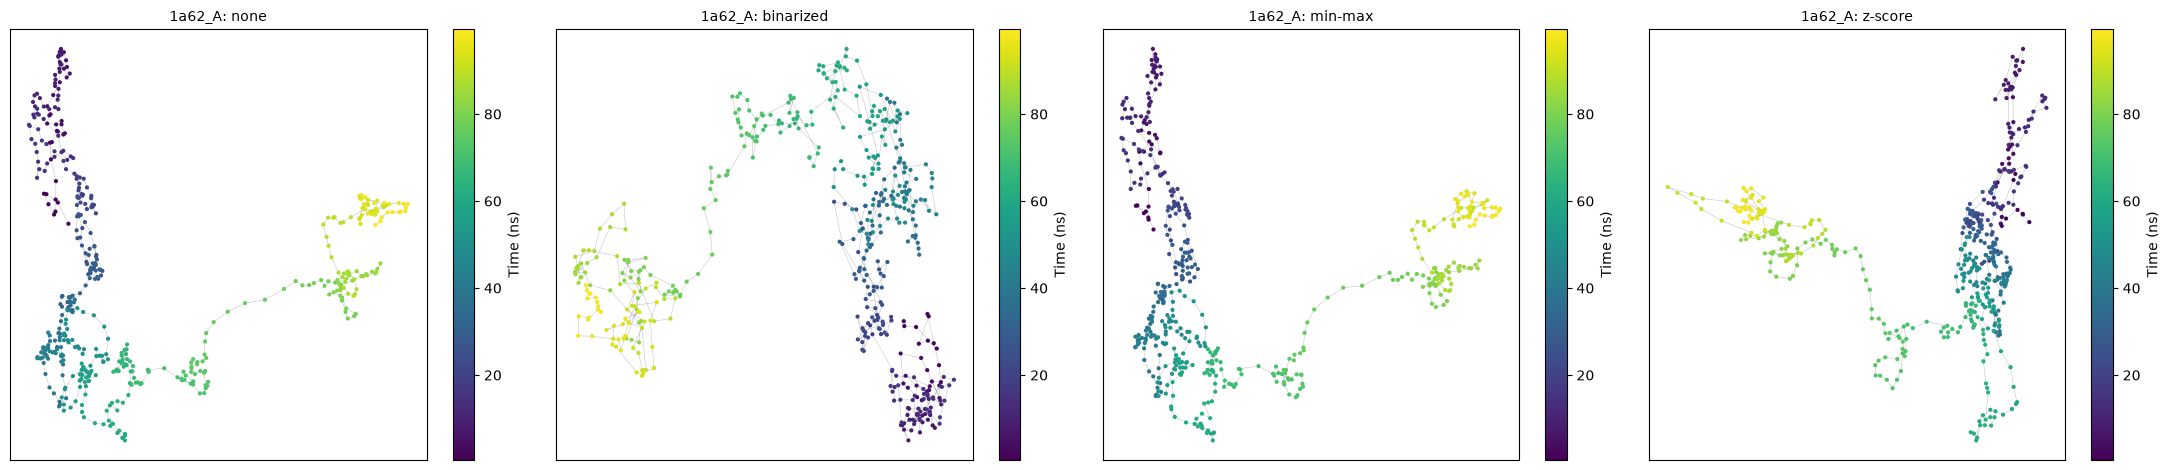

In [19]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

WIDTH, OVERLAP = 20, 0.8          # change after looking at the grid in A
STEP = step_for(WIDTH, OVERLAP)

W = window_mean(F, WIDTH, STEP)
tW = window_mean(t, WIDTH, STEP)

variants = {
    "none": W,
    "binarized": (W > 0).astype(float),
    "min-max": MinMaxScaler().fit_transform(W),
    "z-score": StandardScaler().fit_transform(W),
}

fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
for ax, (name, V) in zip(axes, variants.items()):
    Y = PCA(n_components=2).fit_transform(V)
    plot_projection(ax, Y, tW, f"{PROTEIN}: {name}", "Time (ns)", connect=True)
plt.tight_layout()
plt.show()

None and min-max look nearly the same and give the clearest structure. Frequencies are already 0–1, so min-max barely changes things.
Binarized is the worst: in a 20-frame window almost every flickering contact appears at least once, so it becomes 1 everywhere, as in the example above. The paper’s binarization was designed for event data such as contacts between students, where “did it happen in this hour” is meaningful.
Z-score gives the same overall shape, mirrored (PCA can flip an axis without meaning), but noisier. It gives contacts that barely change as much weight as ones that change a lot, so small random variations get amplified.

### C. Time vs. PC1

Instead of two principal components, plot time on the x-axis and PC1 on the y-axis (paper Figs. 9a and 11a).
Stable states appear as **flat stretches**, transitions as **jumps**, and a recurring state as a **return to an earlier level**.
This is the easiest way to see *when* something happens; for 1a62_A, check whether a jump appears near 77 ns.

All three proteins are shown with the window setting from B.

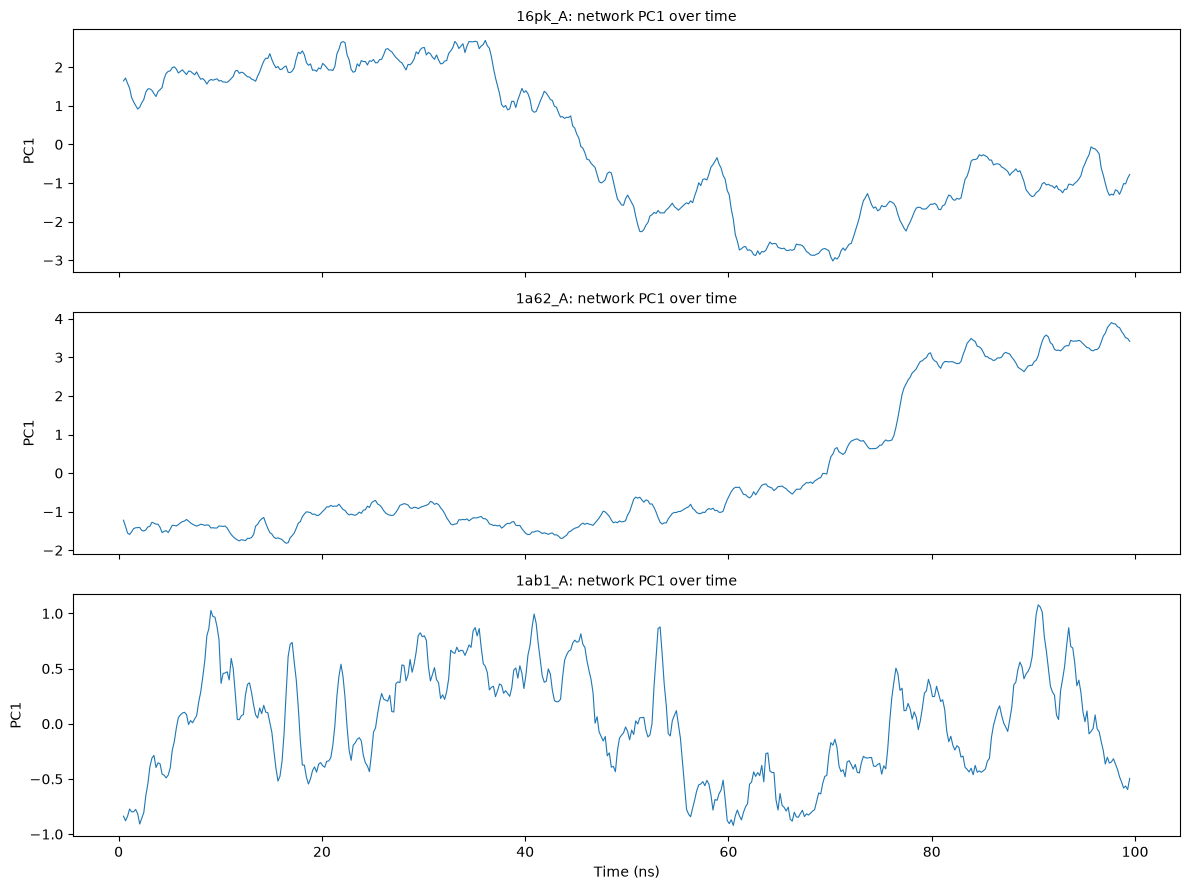

In [20]:
fig, axes = plt.subplots(len(proteins), 1, figsize=(12, 3 * len(proteins)), sharex=True)
for ax, p in zip(axes, proteins):
    Wp = window_mean(network[p]["features"], WIDTH, STEP)
    tp = window_mean(data[p]["time_ns"], WIDTH, STEP)
    pc1 = PCA(n_components=1).fit_transform(Wp)[:, 0]
    ax.plot(tp, pc1, lw=0.8)
    ax.set_ylabel("PC1")
    ax.set_title(f"{p}: network PC1 over time", fontsize=10)
axes[-1].set_xlabel("Time (ns)")
plt.tight_layout()
plt.show()

flat stretch: the network stays in one state (stable state),
jump: transition,
return to an earlier level: recurring state.

### D. Colouring by derived attributes

The same projection coloured by properties of each snapshot instead of time (paper Section 3.6):

- **Number of changing contacts present**: the sum of contact frequencies in the window. Higher means a more compact protein, with more parts touching.
- **RMSD to the first frame**, averaged over the window.

If a cluster stands out in one of these colourings, that property helps explain what makes the state different.

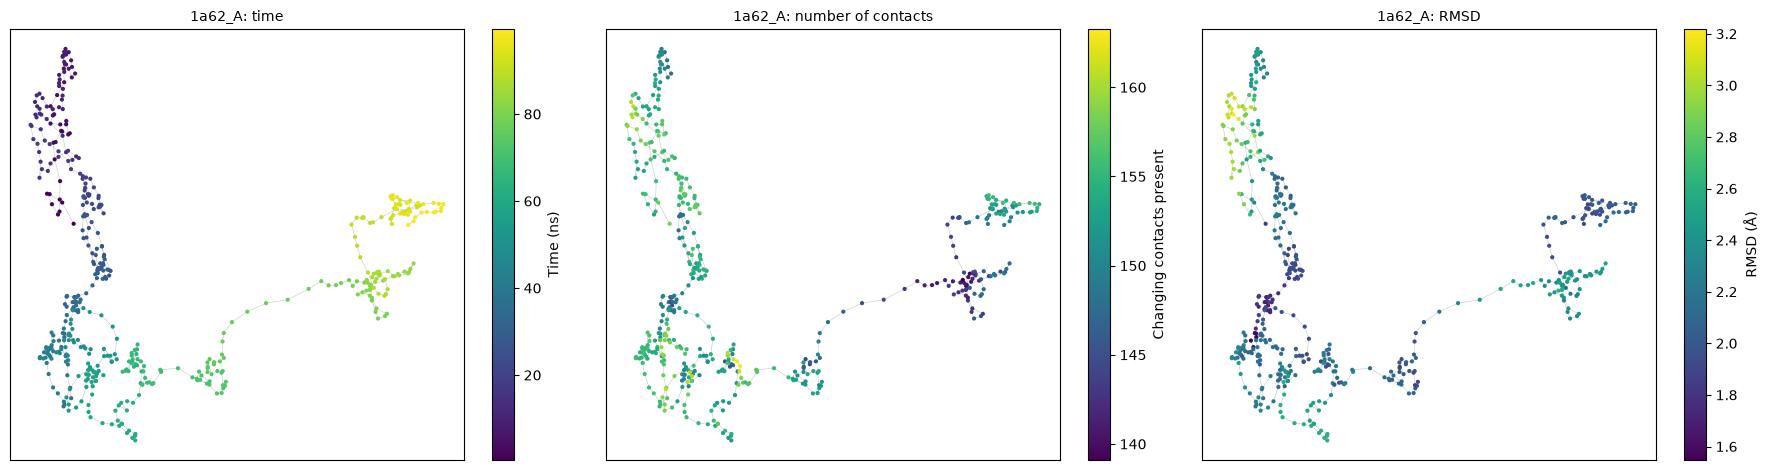

In [21]:
Y = PCA(n_components=2).fit_transform(W)
n_contacts = W.sum(axis=1)
rmsdW = window_mean(data[PROTEIN]["rmsd"], WIDTH, STEP)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
plot_projection(axes[0], Y, tW, f"{PROTEIN}: time", "Time (ns)", connect=True)
plot_projection(axes[1], Y, n_contacts, f"{PROTEIN}: number of contacts", "Changing contacts present", connect=True)
plot_projection(axes[2], Y, rmsdW, f"{PROTEIN}: RMSD", "RMSD (Å)", connect=True)
plt.tight_layout()
plt.show()

### E. Representative states

The paper identifies states visually and shows a representative network for each (Figs. 1 and 8).
Here we group the windowed snapshots into `N_STATES` groups with k-means (an automatic shortcut; the paper suggests automatic clustering as future work),
then show for each state:

- where it lies in the projection and when it occurs in time,
- its **average contact map**: how often each residue pair is in contact within that state.

Set `N_STATES` to the number of clusters you see in the projection. The contact maps include the contacts that never change, so they look like the full contact maps from step 4.

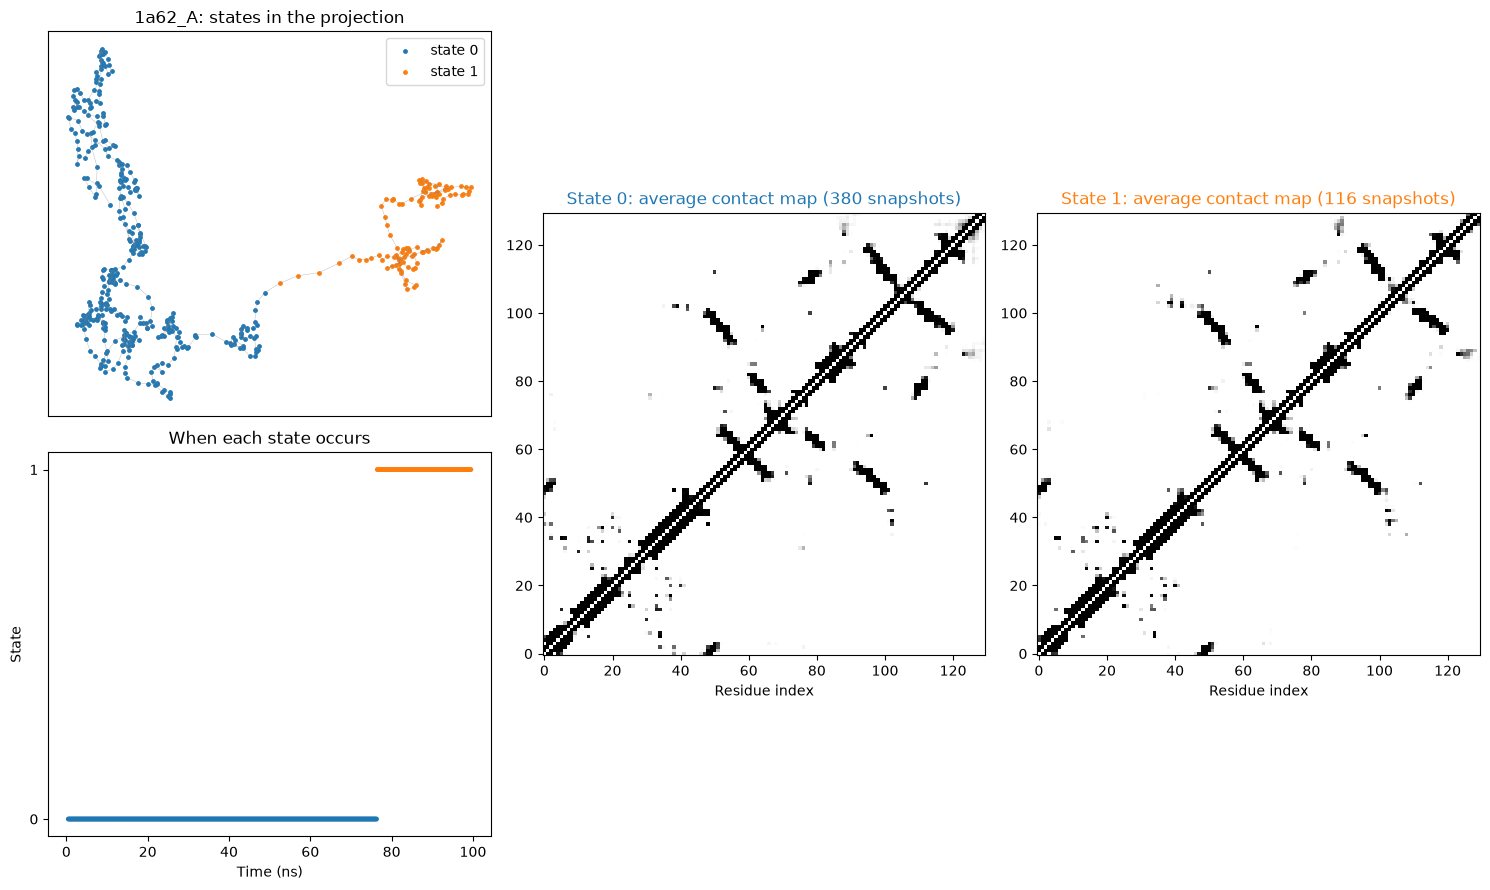

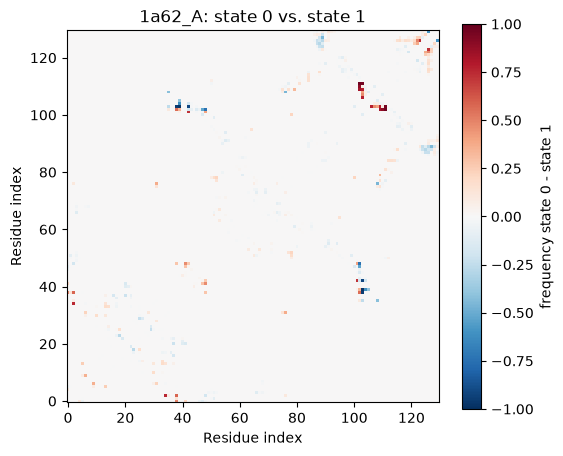

In [22]:
from sklearn.cluster import KMeans

N_STATES = 2
labels = KMeans(n_clusters=N_STATES, n_init=10, random_state=RANDOM_STATE).fit_predict(W)
colours = plt.cm.tab10(np.arange(N_STATES))

# Rebuild full contact frequencies: varying contacts from W, plus contacts that are always present
coords = data[PROTEIN]["coords"]
N = coords.shape[1]
varying = network[PROTEIN]["varying_mask"]
always_on = (pdist(coords[0]) < CONTACT_THRESHOLD) & ~varying

def state_contact_map(state):
    freq = np.zeros(varying.size)
    freq[varying] = W[labels == state].mean(axis=0)
    freq[always_on] = 1.0
    return squareform(freq)

fig = plt.figure(figsize=(6 + 4.5 * N_STATES, 9))
grid = fig.add_gridspec(2, 1 + N_STATES)

ax = fig.add_subplot(grid[0, 0])
ax.plot(Y[:, 0], Y[:, 1], lw=0.3, c="gray", alpha=0.6)
for s in range(N_STATES):
    ax.scatter(*Y[labels == s].T, s=6, color=colours[s], label=f"state {s}")
ax.legend(); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{PROTEIN}: states in the projection")

ax = fig.add_subplot(grid[1, 0])
ax.scatter(tW, labels, c=colours[labels], s=6)
ax.set_yticks(range(N_STATES)); ax.set_xlabel("Time (ns)"); ax.set_ylabel("State"); ax.set_title("When each state occurs")

for s in range(N_STATES):
    ax = fig.add_subplot(grid[:, 1 + s])
    ax.imshow(state_contact_map(s), origin="lower", cmap="Greys", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(f"State {s}: average contact map ({(labels == s).sum()} snapshots)", color=colours[s])
    ax.set_xlabel("Residue index")
plt.tight_layout()
plt.show()

if N_STATES >= 2:
    diff = state_contact_map(0) - state_contact_map(1)
    plt.figure(figsize=(6, 5))
    plt.imshow(diff, origin="lower", cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
    plt.colorbar(label="frequency state 0 - state 1")
    plt.title(f"{PROTEIN}: state 0 vs. state 1"); plt.xlabel("Residue index"); plt.ylabel("Residue index")
    plt.show()

### Observations (section 7)
 
Windows: width 20 frames (1 ns) with 0.8–0.9 overlap gave the clearest structure. Wider windows remove contact flickering; more overlap turns separate snapshots into a continuous path. Width 50 smooths away detail.
Normalization: none and min-max work best and look nearly identical. Binarization loses most structure, because almost every flickering contact appears at least once per window. Z-score shows the same shape but noisier, since it amplifies rare contacts.
Time vs. PC1: 1a62_A is flat until ~45 ns, rises gradually from ~50–75 ns and jumps sharply at ~77 ns, matching the distance analysis. 16pk_A shows several plateaus (0–37 ns, ~60–70 ns) with transitions between them. 1ab1_A fluctuates without clear plateaus.
Derived attributes: the late 1a62_A state has fewer changing contacts, with the fewest during the transition. RMSD does not separate the two states, while the contact network does.
Paper’s terms: 1a62_A has two stable states and one transition (k-means splits at ~76 ns without switching back). 16pk_A shows a sequence of 3–4 states. 1ab1_A is one recurring state.